# Gambler's ruin: a custom function

In Radiant: **Load example > Gambler's ruin (custom function)**.

## Question

> You start with $1,000 and each day bet 5% of what you have. You win with probability 0.2, and a win pays 5 times the bet; otherwise you lose the bet. What is your wealth after a year (365 bets)? How likely are you to end with less than you started with?

In [1]:
import pyrsm as rsm

Each row is a day; `win` is 1 on a winning day. Wealth depends on yesterday's wealth, so it is calculated in a loop: a **custom function**, an ordinary Python function passed in the spec under `functions`. It uses the simulation functions (`zeros`, `ifelse`, `mean`, ...) imported from `pyrsm.decide.simfuns`, so it can be tried on its own; inside a simulation it runs with the same safety rules as in Radiant (no imports, files or `.` attributes). Constants are single numbers, so they can be passed in as they are.

In [2]:
from pyrsm.decide.simfuns import zeros


def calc_wealth(win, start, perc_invest, win_mult):
    # wealth at the end of each day: bet a share of what you have
    wealth = zeros(len(win))
    current = start
    for day in range(len(win)):
        bet = perc_invest * current
        if win[day] == 1:
            current = current + win_mult * bet
        else:
            current = current - bet
        wealth[day] = current
    return wealth


spec = {
    "name": "gamble",
    "runs": 365,
    "seed": 1234,
    "variables": [
        {"name": "start", "kind": "constant", "value": 1000},
        {"name": "perc_invest", "kind": "constant", "value": 0.05},
        {"name": "win_mult", "kind": "constant", "value": 5},
        {"name": "win", "kind": "binomial", "trials": 1, "prob": 0.2},
    ],
    "formulas": [
        "wealth = calc_wealth(win, start, perc_invest, win_mult)",
        "final = wealth[-1]",
        "loss = final < start",
    ],
    "functions": [calc_wealth],
}

In [3]:
import numpy as np

calc_wealth(np.array([1, 0, 0, 1]), 1000, 0.05, 5)

array([1250.     , 1187.5    , 1128.125  , 1410.15625])

In [4]:
sim = rsm.decide.simulate(spec)
sim.summary()

Simulation
Simulations: 365
Random seed: 1234
Sim data   : gamble
Binomial   : win 1 0.2
Constant   : start 1000; perc_invest 0.05; win_mult 5
Functions  : calc_wealth
Formulas   :
	wealth = calc_wealth(win, start, perc_invest, win_mult)
	final = wealth[-1]
	loss = final < start

Constants:
      start perc_invest win_mult      final
 1,000.0000      0.0500   5.0000 6,428.3055

Variables:
        n_obs       mean         sd        min        p25     median        p75         max
 win      365     0.2055     0.4046     0.0000     0.0000     0.0000     0.0000      1.0000
 wealth   365 6,884.5785 3,074.2580 1,148.5811 4,798.5019 6,506.0783 9,344.2592 15,016.3039

Logicals:
      TRUE (nr) TRUE (prop)
 loss         0      0.0000


One simulated year is one path. Repeat it 1,000 times (**group by Repeat**) and keep the `last` value (wealth at the end of the year) and the `min` (the lowest point of the year):

In [5]:
rep = rsm.decide.repeat_simulate(
    spec,
    reps=1000,
    vars=["win"],
    sum_vars=["wealth"],
    by="rep",
    fun=["last", "min"],
    formulas=[
        "loss = wealth_last < 1000",
        "ruined = wealth_min < 100",
    ],
    seed=1234,
)
rep.summary()

Repeated simulation
Simulations   : 365
Repetitions   : 1,000
Re-simulated  : win
Group by      : Repeat
Function      : last, min
Random  seed  : 1234
Simulated data: gamble
Formulas      :
	loss = wealth_last < 1000
	ruined = wealth_min < 100

Variables:
             n_obs        mean           sd    min      p25     median         p75            max
 wealth_last 1,000 44,826.3525 304,805.5250 3.8910 941.4379 3,712.9893 14,643.8655 6,134,182.6367
 wealth_min  1,000    477.6254     294.8012 3.8217 227.8784   452.8243    705.6325     1,250.0000

Logicals:
        TRUE (nr) TRUE (prop)
 loss         262      0.2620
 ruined       101      0.1010


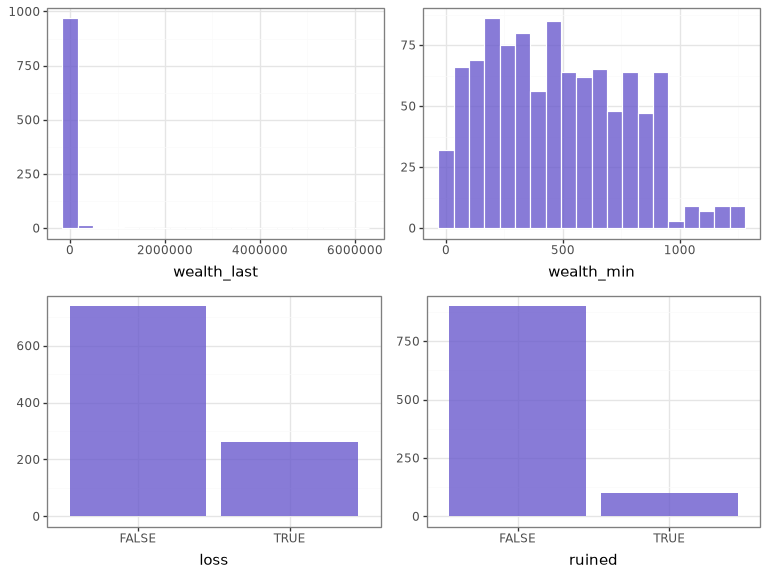

In [6]:
rep.plot()

A loop is easy to read but slow for long simulations. The same wealth without a loop: each day multiplies wealth by `1 + 5 x 0.05` or `1 - 0.05`, so

In [7]:
fast = dict(spec, formulas=["wealth = start * cum_prod(ifelse(win == 1, 1 + win_mult * perc_invest, 1 - perc_invest))"])
fast.pop("functions")
(rsm.decide.simulate(fast).data["wealth"] - sim.data["wealth"]).abs().max()

1.4006218407303095e-10